# 01. Data Overview

## HR Analytics: 직원 이직 요인 및 조직 관리 분석

### 1. 분석 목적

본 단계에서는 IBM HR Analytics 데이터를 활용하여 직원들의 인사 정보와 데이터 구조를 파악하고, 향후 분석에 활용할 수 있는 데이터인지 검토한다.

본격적인 분석에 앞서 데이터의 크기, 변수 구성, 데이터 타입, 결측치, 중복 데이터 및 이상치 등을 확인하여 데이터 품질을 점검하고자 한다.

### 2. 주요 점검 항목

- 데이터 구조 및 변수 구성 확인
- 데이터 타입 및 변수별 고유값 확인
- 결측치 및 중복 데이터 확인
- 수치형·범주형 변수 구분
- 기초통계량 및 데이터 분포 확인
- 이상치 탐색 및 데이터 품질 평가

### 3. 분석 환경

| 구분 | 도구 |
|---|---|
| 데이터 처리 | Python, Pandas, NumPy |
| 데이터 시각화 | Matplotlib, Seaborn |
| 분석 환경 | Jupyter Notebook |

> **데이터 출처·라이선스:** IBM HR Analytics Employee Attrition & Performance(IBM 데이터 과학자가 만든 가상 데이터. [Kaggle](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset), [IBM/employee-attrition-aif360](https://github.com/IBM/employee-attrition-aif360)). 데이터베이스는 [ODbL 1.0](https://opendatacommons.org/licenses/odbl/1-0/), 개별 내용은 [DbCL 1.0](https://opendatacommons.org/licenses/dbcl/1-0/)으로 표기되어 있습니다. 이 Notebook의 출력(표·그림·수치)은 이 데이터에서 만든 결과물이며, MIT License(`../LICENSE`)는 코드에만 적용됩니다. 전처리 CSV(ODbL 1.0)와 전처리 방법은 `../data/README.md`를 참고하세요.
>
> Contains information from the IBM HR Analytics Employee Attrition & Performance dataset, which is made available here under the Open Database License (ODbL) 1.0.

# 데이터 불러오기

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 시각화 기본 설정
plt.rcParams["figure.figsize"] = (10, 5)
sns.set_theme(style="whitegrid")


In [2]:

import os

file_path = "../data/raw/hr.csv"

hr_df = pd.read_csv(file_path)

print("데이터 로드 완료")


데이터 로드 완료


In [4]:
display(hr_df.head())

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


# 데이터 구조 및 크기 확인

In [5]:
print("행과 열 개수:", hr_df.shape)
print("전체 데이터 개수:", hr_df.size)
print("컬럼 개수:", len(hr_df.columns))

행과 열 개수: (1470, 35)
전체 데이터 개수: 51450
컬럼 개수: 35


In [6]:
print("전체 컬럼 목록")

for idx, col in enumerate(hr_df.columns, start=1):
    print(f"{idx}. {col}")

전체 컬럼 목록
1. Age
2. Attrition
3. BusinessTravel
4. DailyRate
5. Department
6. DistanceFromHome
7. Education
8. EducationField
9. EmployeeCount
10. EmployeeNumber
11. EnvironmentSatisfaction
12. Gender
13. HourlyRate
14. JobInvolvement
15. JobLevel
16. JobRole
17. JobSatisfaction
18. MaritalStatus
19. MonthlyIncome
20. MonthlyRate
21. NumCompaniesWorked
22. Over18
23. OverTime
24. PercentSalaryHike
25. PerformanceRating
26. RelationshipSatisfaction
27. StandardHours
28. StockOptionLevel
29. TotalWorkingYears
30. TrainingTimesLastYear
31. WorkLifeBalance
32. YearsAtCompany
33. YearsInCurrentRole
34. YearsSinceLastPromotion
35. YearsWithCurrManager


In [7]:
hr_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

# 컬럼별 데이터 타입과 고유값 확인

In [8]:
column_info = pd.DataFrame({
    "column": hr_df.columns,
    "dtype": hr_df.dtypes.values,
    "unique_count": hr_df.nunique().values
})

display(column_info)

,column,dtype,unique_count
0,Age,int64,43
1,Attrition,object,2
2,BusinessTravel,object,3
3,DailyRate,int64,886
4,Department,object,3
5,DistanceFromHome,int64,29
6,Education,int64,5
7,EducationField,object,6
8,EmployeeCount,int64,1
9,EmployeeNumber,int64,1470


In [10]:
# 중복 데이터 확인 
print("완전 중복 행:", hr_df.duplicated().sum())

# 직원 식별자 중복 확인
print(
    "EmployeeNumber 중복:",
    hr_df["EmployeeNumber"].duplicated().sum()
)

완전 중복 행: 0
EmployeeNumber 중복: 0


# 수치형 및 범주형 변수 분리

In [12]:
numeric_cols = hr_df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = hr_df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("수치형 변수:", len(numeric_cols))
print(numeric_cols)

print("\n범주형 변수:", len(categorical_cols))
print(categorical_cols)

수치형 변수: 26
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

범주형 변수: 9
['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']


In [13]:
# 고유값이 하나뿐인 컬럼
constant_cols = [
    col for col in hr_df.columns
    if hr_df[col].nunique() <= 1
]

print("고유값이 1개인 컬럼:")
print(constant_cols)

# 식별자 컬럼
id_cols = ["EmployeeNumber", "EmployeeCount", "Over18", "StandardHours"]

display(hr_df[id_cols].head())


고유값이 1개인 컬럼:
['EmployeeCount', 'Over18', 'StandardHours']


,EmployeeNumber,EmployeeCount,Over18,StandardHours
0,1,1,Y,80
1,2,1,Y,80
2,4,1,Y,80
3,5,1,Y,80
4,7,1,Y,80


# 기초통계량 확인

In [17]:
#수치형 변수 통계량
display(
    hr_df.describe().T.round(2).style.background_gradient(cmap="Blues")
)

,count,mean,std,min,25%,50%,75%,max
Age,1470.000000,36.920000,9.140000,18.000000,30.000000,36.000000,43.000000,60.000000
DailyRate,1470.000000,802.490000,403.510000,102.000000,465.000000,802.000000,1157.000000,1499.000000
DistanceFromHome,1470.000000,9.190000,8.110000,1.000000,2.000000,7.000000,14.000000,29.000000
Education,1470.000000,2.910000,1.020000,1.000000,2.000000,3.000000,4.000000,5.000000
EmployeeCount,1470.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
EmployeeNumber,1470.000000,1024.870000,602.020000,1.000000,491.250000,1020.500000,1555.750000,2068.000000
EnvironmentSatisfaction,1470.000000,2.720000,1.090000,1.000000,2.000000,3.000000,4.000000,4.000000
HourlyRate,1470.000000,65.890000,20.330000,30.000000,48.000000,66.000000,83.750000,100.000000
JobInvolvement,1470.000000,2.730000,0.710000,1.000000,2.000000,3.000000,3.000000,4.000000
JobLevel,1470.000000,2.060000,1.110000,1.000000,1.000000,2.000000,3.000000,5.000000


In [16]:
# 범주형 변수 통계량
display(
    hr_df.describe(include="object").T
)

,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054


In [18]:
# 이직 여부 분포 확인
attrition_counts = hr_df["Attrition"].value_counts()

attrition_ratio = (
    hr_df["Attrition"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(
    pd.DataFrame({
        "count": attrition_counts,
        "percentage": attrition_ratio
    })
)


,count,percentage
Attrition,,
No,1233,83.88
Yes,237,16.12


# 이상치 및 데이터 분포 확인

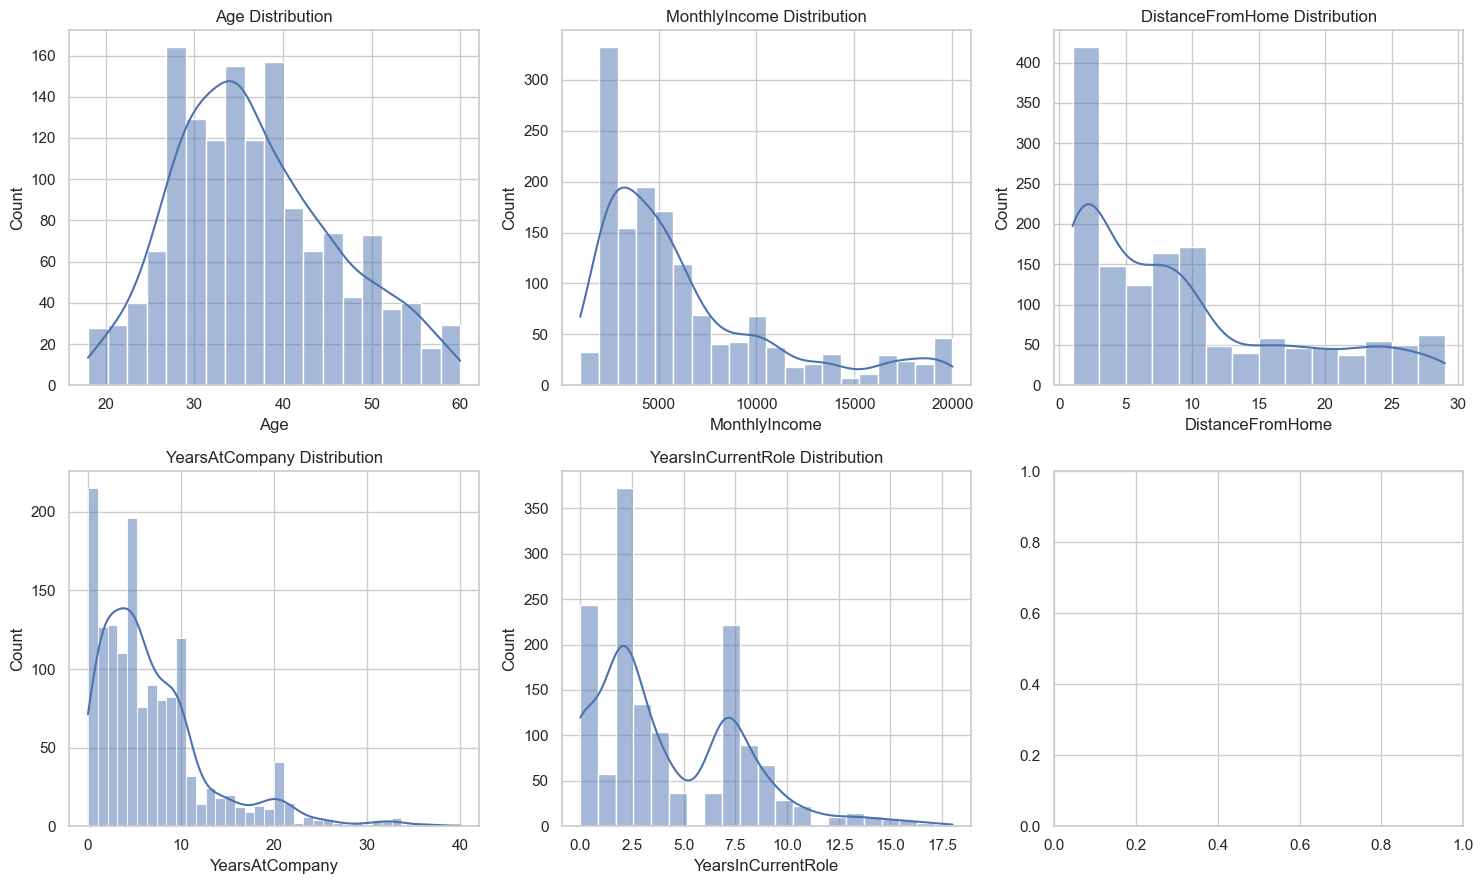

In [20]:
# 주요 변수 분포 확인
target_cols = [
    "Age",
    "MonthlyIncome",
    "DistanceFromHome",
    "YearsAtCompany",
    "YearsInCurrentRole"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(target_cols):
    sns.histplot(
        data=hr_df,
        x=col,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(f"{col} Distribution")

plt.tight_layout()
plt.show()


In [22]:
# 이상치 탐색
outlier_results = []

for col in numeric_cols:
    Q1 = hr_df[col].quantile(0.25)
    Q3 = hr_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_count = (
        (hr_df[col] < lower) |
        (hr_df[col] > upper)
    ).sum()

    outlier_results.append({
        "column": col,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": outlier_count,
        "outlier_pct": round(
            outlier_count / len(hr_df) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_results)

display(
    outlier_df.sort_values(
        by="outlier_pct",
        ascending=False
    )
)

,column,lower_bound,upper_bound,outlier_count,outlier_pct
20,TrainingTimesLastYear,0.500,4.500,238,16.19
15,PerformanceRating,3.000,3.000,226,15.37
11,MonthlyIncome,-5291.000,16581.000,114,7.76
24,YearsSinceLastPromotion,-4.500,7.500,107,7.28
22,YearsAtCompany,-6.000,18.000,104,7.07
18,StockOptionLevel,-1.500,2.500,85,5.78
19,TotalWorkingYears,-7.500,28.500,63,4.29
13,NumCompaniesWorked,-3.500,8.500,52,3.54
23,YearsInCurrentRole,-5.500,14.500,21,1.43
25,YearsWithCurrManager,-5.500,14.500,14,0.95


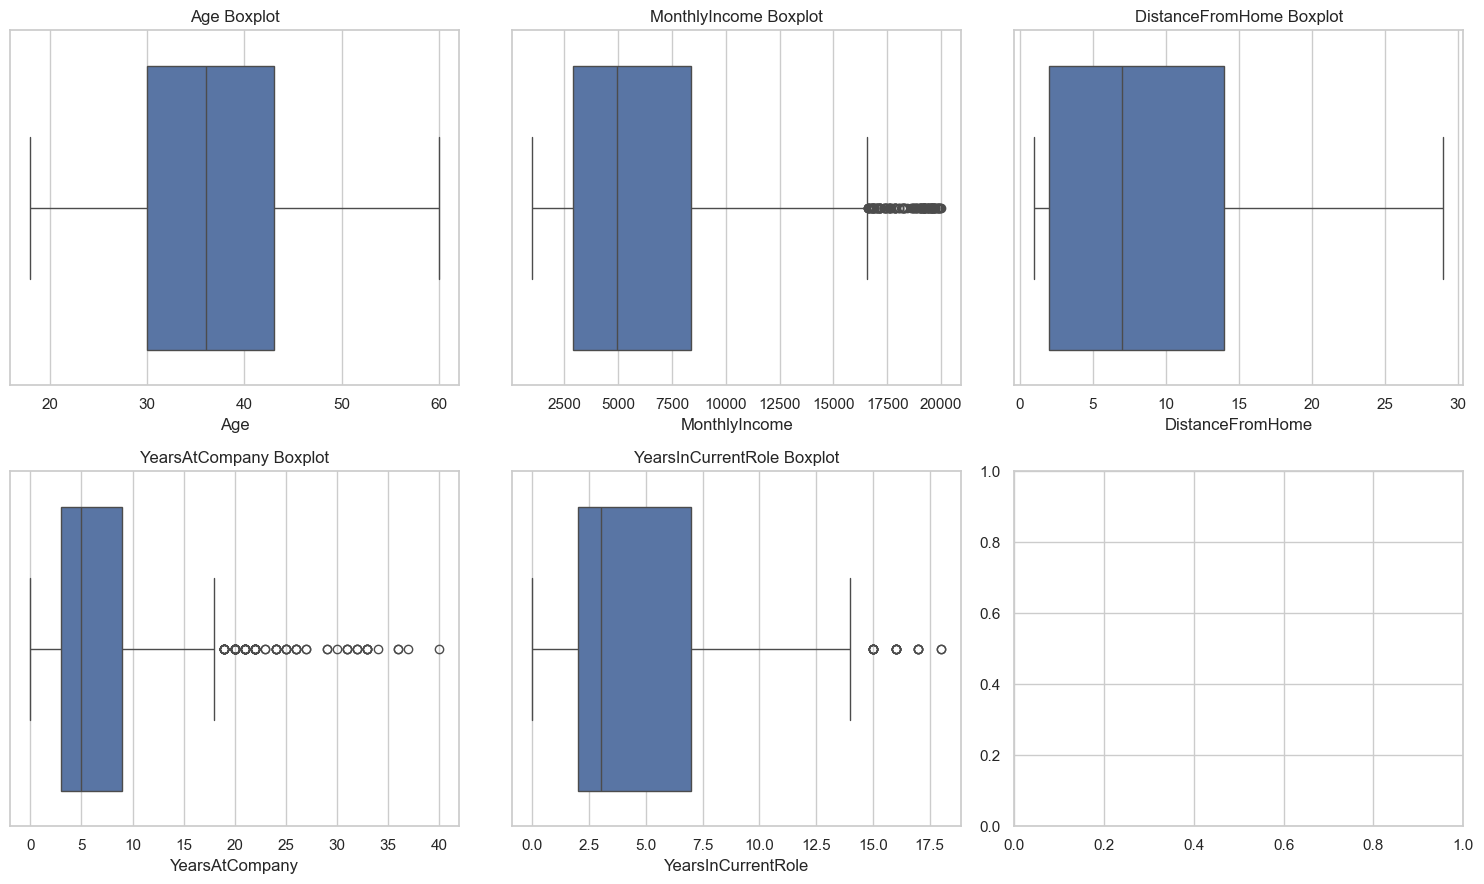

In [23]:
# 주요 변수 boxplot
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(target_cols):
    sns.boxplot(
        data=hr_df,
        x=col,
        ax=axes[i]
    )
    axes[i].set_title(f"{col} Boxplot")

plt.tight_layout()
plt.show()


# 데이터 품질 점검 결과 정리

In [24]:
# 최종 데이터 품질 정리

quality_summary = pd.DataFrame({
    "항목": [
        "전체 행",
        "전체 컬럼",
        "결측치 개수",
        "완전 중복 행",
        "직원번호 중복",
        "수치형 변수 개수",
        "범주형 변수 개수"
    ],
    "결과": [
        len(hr_df),
        len(hr_df.columns),
        hr_df.isnull().sum().sum(),
        hr_df.duplicated().sum(),
        hr_df["EmployeeNumber"].duplicated().sum(),
        len(numeric_cols),
        len(categorical_cols)
    ]
})

display(quality_summary)


,항목,결과
0,전체 행,1470
1,전체 컬럼,35
2,결측치 개수,0
3,완전 중복 행,0
4,직원번호 중복,0
5,수치형 변수 개수,26
6,범주형 변수 개수,9



## 9. 데이터 품질 점검 결과

### 9-1. 데이터 구조

- 전체 데이터 크기: 1470
- 전체 변수 개수: 35
- 수치형 변수: 26
- 범주형 변수: 9

### 9-2. 데이터 품질

- 결측치: 0
- 완전 중복 데이터: 0
- 직원 식별번호 중복: 0

### 9-3. 주요 확인 사항

- 이직 여부의 클래스 분포 확인
- 수치형 변수별 분포 및 편차 확인
- 범주형 변수의 고유값 확인
- 분석에서 제외할 식별자 및 상수 변수 검토

### 9-4. 다음 진행 내용

데이터 구조와 품질을 확인하였으며,
다음 단계에서는 분석 목적에 맞는 변수 선정,
데이터 전처리 및 파생변수 생성을 진행한다.
